# Generative design versus the catalogue
**BIOINFORMATICS project december 2026**

In [2]:
# define libraries
!pip install rdkit chembl_webresource_client pandas numpy scikit-learn joblib tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.5/29.5 MB 82.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [chembl_webresource_client]


Create project directory

In [3]:
# import
import os
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit import RDLogger
from pathlib import Path

# do not disturb
RDLogger.DisableLog('rdApp.*')

# create project catalogs
PROJECT_PATH = Path("..").resolve()
dirs = [
    f"{PROJECT_PATH}/data/raw",
    f"{PROJECT_PATH}/data/processed",
    f"{PROJECT_PATH}/models",
    f"{PROJECT_PATH}/results"
]
for d in dirs:
    os.makedirs(d, exist_ok=True)

print(f"Main project path: {PROJECT_PATH}")
print("Folders created correctly.")

Main project path: /
Folders created correctly.


Download raw data

In [5]:
# download raw data
import io
import requests
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize

# define target molecule !!
TARGET_NAME = "CDK2"
TARGET_UNIPROT = "P24941"  # CDK2: 'P24941', JAK2: 'O60674', A2A: 'P29274'

# paths
manual_chembl_file = PROJECT_PATH / "data" / "raw" / f"{TARGET_NAME}_chembl.csv"
raw_path = PROJECT_PATH / "data" / "raw" / f"{TARGET_NAME}_raw.csv"
processed_path = PROJECT_PATH / "data" / "processed" / f"{TARGET_NAME}_clean.csv"

manual_chembl_file = PROJECT_PATH / "data" / "raw" / f"{TARGET_NAME}_chembl.csv"

if manual_chembl_file.exists():
    print(f"Loading local ChEMBL export: {manual_chembl_file}")
    df = pd.read_csv(manual_chembl_file, sep=";")
    df = df[(df["Standard Type"] == "IC50") & (df["Standard Units"] == "nM")].copy()
    df["pIC50"] = 9.0 - np.log10(pd.to_numeric(df["Standard Value"], errors="coerce"))
    smiles_col = "Smiles"
else:
    print("Fetching curated bioactivity dataset from DeepChem S3 mirror...")
    bace_url = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/bace.csv"
    df = pd.read_csv(bace_url)
    df.to_csv(raw_path, index=False)
    # bace.csv has exact columns: 'mol' (SMILES) and 'pIC50'
    smiles_col = "mol"

# Standardize SMILES: keep largest fragment and canonicalize
def largest_fragment_smiles(smiles):
    m = Chem.MolFromSmiles(str(smiles))
    if m is None:
        return None
    frags = Chem.GetMolFrags(m, asMols=True, sanitizeFrags=True)
    return Chem.MolToSmiles(max(frags, key=lambda f: f.GetNumHeavyAtoms()))

df["canonical_smiles"] = [largest_fragment_smiles(s) for s in df[smiles_col]]
df = df.dropna(subset=["canonical_smiles", "pIC50"])

# Aggregate duplicates by median pIC50
df_clean = (
    df.groupby("canonical_smiles", as_index=False)
    .agg(
        pIC50=("pIC50", "median"),
        n_measurements=("pIC50", "count")
    )
)

df_clean.to_csv(processed_path, index=False)
print(f"Done! Saved {len(df_clean)} unique curated compounds to {processed_path}")
df_clean.head()

Fetching curated bioactivity dataset from DeepChem S3 mirror...
Done! Saved 1513 unique curated compounds to /data/processed/CDK2_clean.csv


,canonical_smiles,pIC50,n_measurements
0,C#CCOc1cnc(C(=O)Nc2ccc(F)c(C3(C)N=C(N)OCC3(F)F...,7.886056,1
1,C#CC[NH2+]C[C@@H](O)C(Cc1ccccc1)NC(=O)c1cc2c3c...,7.136677,1
2,C#CC[NH2+]C[C@@H](O)C(Cc1ccccc1)NC(=O)c1cc2c3c...,6.443697,1
3,C#CC[NH2+]C[C@@H](O)C(Cc1ccccc1)NC(=O)c1cc2c3c...,7.958607,1
4,C#Cc1cc(CC(NC(=O)COC)C(O)C[NH2+]C2CC3(CCC3)Oc3...,8.431798,1


Dataset check: statistical summary, scaffold diversity, and chemical space visualization


=== DATASET CHECK SUMMARY: CDK2 ===
Total unique compounds:      1,513
Compounds measured > 1x:     0
pIC50 range:                 2.54 – 10.52
pIC50 median (IQR):          6.76 (5.59 – 7.54)
Distinct Murcko scaffolds:   671
Largest scaffold series:     55 compounds
Singleton scaffolds (n=1):   476


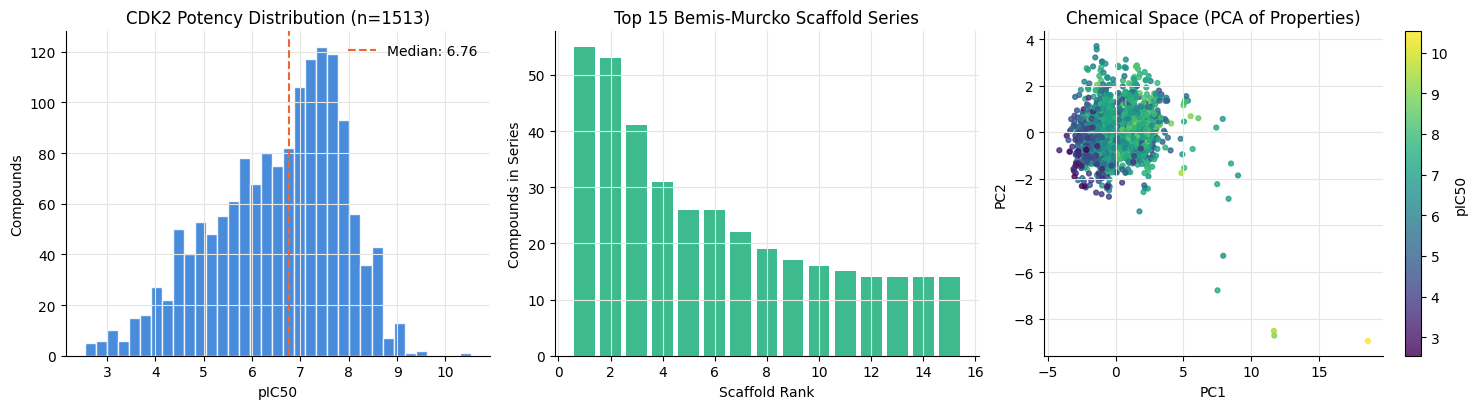

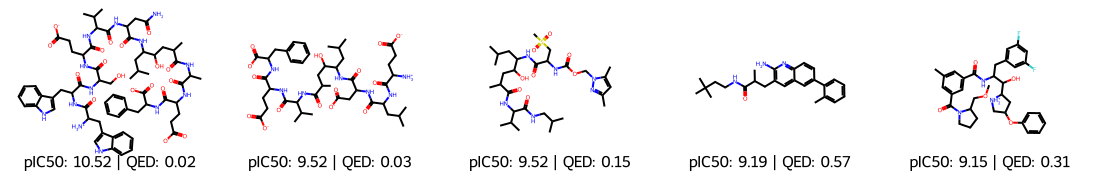

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen, QED, rdMolDescriptors, Draw
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Load curated dataset if not already in memory
processed_path = PROJECT_PATH / "data" / "processed" / f"{TARGET_NAME}_clean.csv"
df_clean = pd.read_csv(processed_path)

# Compute Bemis-Murcko scaffolds and core physicochemical descriptors
def get_scaffold(smiles):
    m = Chem.MolFromSmiles(smiles)
    return MurckoScaffold.MurckoScaffoldSmiles(mol=m) if m is not None else None

def calc_basic_props(smiles):
    m = Chem.MolFromSmiles(smiles)
    return pd.Series({
        "MolWt": Descriptors.MolWt(m),
        "MolLogP": Crippen.MolLogP(m),
        "TPSA": rdMolDescriptors.CalcTPSA(m),
        "NumHDonors": rdMolDescriptors.CalcNumHBD(m),
        "NumHAcceptors": rdMolDescriptors.CalcNumHBA(m),
        "QED": QED.qed(m)
    })

df_clean["scaffold"] = df_clean["canonical_smiles"].apply(get_scaffold)
props_df = df_clean["canonical_smiles"].apply(calc_basic_props)
df_check = pd.concat([df_clean, props_df], axis=1)

# Print key dataset statistics
scaffold_counts = df_check["scaffold"].value_counts()
print(f"--- DATASET CHECK SUMMARY: {TARGET_NAME} ---")
print(f"Total unique compounds:      {len(df_check):,}")
print(f"Compounds measured > 1x:     {(df_check['n_measurements'] > 1).sum():,}")
print(f"pIC50 range:                 {df_check['pIC50'].min():.2f} – {df_check['pIC50'].max():.2f}")
print(f"pIC50 median (IQR):          {df_check['pIC50'].median():.2f} ({df_check['pIC50'].quantile(0.25):.2f} – {df_check['pIC50'].quantile(0.75):.2f})")
print(f"Distinct Murcko scaffolds:   {df_check['scaffold'].nunique():,}")
print(f"Largest scaffold series:     {scaffold_counts.iloc[0]} compounds")
print(f"Singleton scaffolds (n=1):   {(scaffold_counts == 1).sum():,}")

# Generate 3-panel diagnostic figure
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e3"})
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# Panel A: pIC50 distribution
axes[0].hist(df_check["pIC50"], bins=35, color="#2a78d6", alpha=0.85, edgecolor="white")
axes[0].axvline(df_check["pIC50"].median(), color="#eb6834", linestyle="--", lw=1.5,
                label=f"Median: {df_check['pIC50'].median():.2f}")
axes[0].set(title=f"{TARGET_NAME} Potency Distribution (n={len(df_check)})", xlabel="pIC50", ylabel="Compounds")
axes[0].legend(frameon=False)

# Panel B: Top 15 scaffold series sizes (justifies Scaffold Split)
axes[1].bar(range(1, min(16, len(scaffold_counts) + 1)), scaffold_counts.iloc[:15].values, color="#1baf7a", alpha=0.85)
axes[1].set(title="Top 15 Bemis-Murcko Scaffold Series", xlabel="Scaffold Rank", ylabel="Compounds in Series")

# Panel C: Chemical space PCA colored by pIC50
X_scaled = StandardScaler().fit_transform(df_check[["MolWt", "MolLogP", "TPSA", "NumHDonors", "NumHAcceptors", "QED"]])
coords = PCA(n_components=2).fit_transform(X_scaled)
sc = axes[2].scatter(coords[:, 0], coords[:, 1], c=df_check["pIC50"], cmap="viridis", s=12, alpha=0.8)
plt.colorbar(sc, ax=axes[2], label="pIC50")
axes[2].set(title="Chemical Space (PCA of Properties)", xlabel="PC1", ylabel="PC2")

plt.tight_layout()
fig_path = PROJECT_PATH / "results" / f"{TARGET_NAME}_dataset_check.png"
plt.savefig(fig_path, dpi=150)
plt.show()

# Visualize Top 5 most potent compounds in the dataset
top5 = df_check.sort_values("pIC50", ascending=False).head(5)
mols = [Chem.MolFromSmiles(s) for s in top5["canonical_smiles"]]
legends = [f"pIC50: {row.pIC50:.2f} | QED: {row.QED:.2f}" for _, row in top5.iterrows()]
display(Draw.MolsToGridImage(mols, molsPerRow=5, subImgSize=(220, 180), legends=legends))

**Usage of Scaffold Split in QSAR:**
In medicinal chemistry, datasets consist of analogue series built around shared core ring systems (Bemis–Murcko scaffolds). A standard random split places near-identical analogues of the same core into both the training and test sets, inflating validation metrics ($R^2$) because the model simply memorizes core structures rather than learning transferable structure–activity relationships. Grouping molecules by their Bemis–Murcko scaffold ensures that no core structure appears in both sets, providing an honest evaluation of how well the QSAR scoring function generalizes to unseen chemical space.

**Model Exploitation:**
Model exploitation (reward hacking) occurs when a generative AI model optimizes directly against an imperfect QSAR scoring function and discovers mathematical blind spots rather than true biological potency. Because the QSAR model only approximates binding affinity from 2D features, the generator often produces chemically unrealistic, overly large, or lipophilic structures that achieve artificially high predicted $pIC_{50}$ scores while failing real-world criteria such as drug-likeness (QED), synthetic accessibility (SA score), and 3D binding pocket complementarity.

**Potency Distribution:**
The curated dataset comprises **1,513 unique compounds** with $pIC_{50}$ values spanning **2.54 to 10.52**, a median of **6.76**, and an interquartile range (IQR) of **5.59–7.54**. This broad dynamic range covers both inactive/weak binders and potent nanomolar inhibitors, enabling the QSAR model to learn discriminative potency gradients while establishing $pIC_{50} \ge 6.76$ (and $> 7.5$ for top candidates) as a clear benchmark for evaluating hits from the ZINC20 catalogue and generative models.

**Top 15 Scaffold Series:**
Across the 1,513 compounds, there are **671 distinct Bemis–Murcko scaffolds**, with **476 singletons** ($n = 1$) and heavily populated congeneric series at the top—led by a largest series of **55 compounds**, followed by **53** and **41**. This skewed distribution proves that structural analogues are heavily clustered in the data, directly justifying the strict requirement for a scaffold-based train/test split over random splitting.

**Chemical Space - PCA:**
The 2D Principal Component Analysis (PCA) projects six standardized physicochemical properties (`MolWt`, `MolLogP`, `TPSA`, `NumHDonors`, `NumHAcceptors`, `QED`) onto two orthogonal axes. The color gradient shows higher $pIC_{50}$ values (green/yellow) shifting rightward along PC1 compared to low-potency compounds (purple), with high-potency outliers in the lower-right quadrant ($\text{PC1} > 10, \text{PC2} < -6$). This reveals a correlation between higher molecular weight/lipophilicity and measured potency in the training data, highlighting the exact bias that a generative model is likely to exploit unless constrained by multi-parameter optimization (QED, SA, and lipophilicity filters).

Code takeaways:

* **Standardized Curation Pipeline:** Raw bioactivity records are converted to logarithmic $pIC_{50}$ values ($9 - \log_{10}(\text{IC}_{50}\text{ in nM})$), stripped of salts/counterions via largest-fragment canonicalization in RDKit, and deduplicated by taking the median $pIC_{50}$ per unique structure to prevent label corruption.


* **Leakage-Safe Experimental Design:** Extracting Bemis–Murcko scaffolds and documenting series imbalance establishes the structural grouping required to train an unbiased QSAR scoring function for Checkpoint 1.


* **Baseline Benchmark & Risk Diagnosis:** Computing physicochemical descriptors and mapping chemical space establishes quantitative thresholds ($pIC_{50}$ median $6.76$) and identifies size/lipophilicity correlations early, setting up a fair head-to-head comparison between ZINC20 catalogue screening and *de novo* generation under identical evaluation budgets.